## Lab: Market Return Dynamics

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 

df = pd.read_parquet('ff_market_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

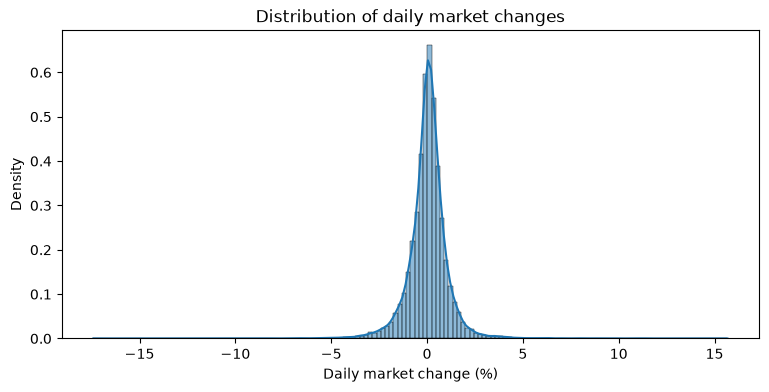

In [2]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

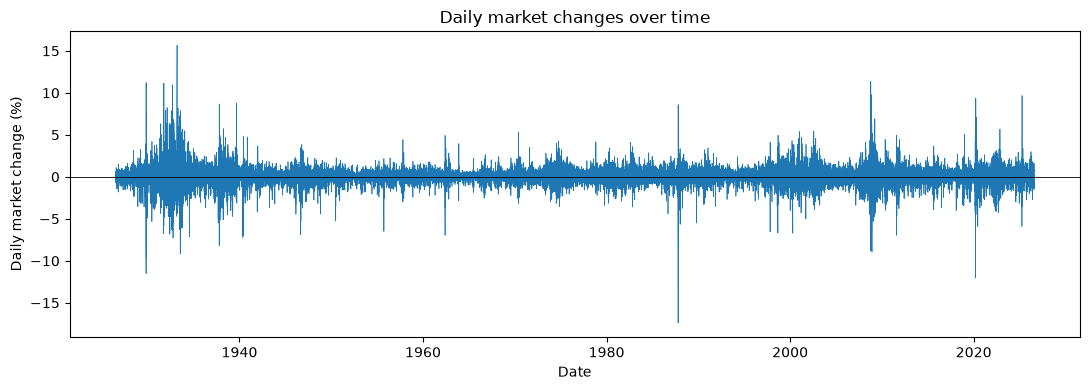

In [3]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

### 1. Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 
- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

In [4]:
df['current_direction'] = ['Up' if i > 0 else 'Down' for i in df['market_return_pct']]

df['next_direction'] = df['current_direction'].shift(-1)
df.head()

,date,year,month,month_start,trading_day_of_month,mkt_excess_return_pct,risk_free_return_pct,market_return_pct,absolute_market_return_pct,current_direction,next_direction
0,1926-07-01,1926,7,1926-07-01,1,0.09,0.01,0.10,0.10,Up,Up
1,1926-07-02,1926,7,1926-07-01,2,0.45,0.01,0.46,0.46,Up,Up
2,1926-07-06,1926,7,1926-07-01,3,0.17,0.01,0.18,0.18,Up,Up
3,1926-07-07,1926,7,1926-07-01,4,0.09,0.01,0.10,0.10,Up,Up
4,1926-07-08,1926,7,1926-07-01,5,0.22,0.01,0.23,0.23,Up,Down


In [5]:
joint_pmf = pd.crosstab(
    df['current_direction'],
    df['next_direction'],
    normalize='all'
)
joint_pmf

next_direction,Down,Up
current_direction,,
Down,0.224720,0.228142
Up,0.228142,0.318996


In [6]:
current_pmf = df['current_direction'].value_counts(normalize=True)
next_pmf = df['next_direction'].value_counts(normalize=True)

print(current_pmf)
print('-----')
print(next_pmf)

current_direction
Up      0.547155
Down    0.452845
Name: proportion, dtype: float64
-----
next_direction
Up      0.547138
Down    0.452862
Name: proportion, dtype: float64


In [7]:
conditional_pmf = pd.crosstab(
    df['current_direction'],
    df['next_direction'],
    normalize='index'
)
conditional_pmf

next_direction,Down,Up
current_direction,,
Down,0.496221,0.503779
Up,0.416974,0.583026


- Up transitions are more common than Down transitions as it does not matter if the current direction is Up or Down, an up transition is more likely in both cases according to the conditional PMF.
- You are more likely to transition to an Up day from an Up day. The conditional PMF tells us that given the current day is an Up day the probability the next day is an Up day is about 0.583 whereas given the current day is an Down day the probability the next day is an Up day is about 0.504. 

### 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?
- Compute the joint PMF and marginals. Which transitions are most likely to occur? 
- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

In [8]:
bins = [-np.inf, -1, -0.1, 0.1, 1, np.inf]

labels = [
    'Large loss',
    'Small loss',
    'Near zero',
    'Small gain',
    'Large gain'
]

df['market_category'] = pd.cut(
    df['market_return_pct'],
    bins=bins,
    labels=labels,
    right=True
)

df['next_category'] = df['market_category'].shift(-1)

df['market_category'].value_counts()

market_category
Small gain    9785
Small loss    7452
Near zero     3441
Large gain    2859
Large loss    2759
Name: count, dtype: int64

The most common category is Small gain and the least common category is Large loss.

In [9]:
joint_pmf = pd.crosstab(
    df['market_category'],
    df['next_category'],
    normalize='all'
)
joint_pmf

next_category,Large loss,Small loss,Near zero,Small gain,Large gain
market_category,,,,,
Large loss,0.021335,0.027191,0.009051,0.027800,0.019547
Small loss,0.035444,0.088648,0.034151,0.097775,0.027382
Near zero,0.009317,0.041985,0.020955,0.049325,0.009279
Small gain,0.024986,0.100057,0.055029,0.159422,0.032592
Large gain,0.013843,0.025518,0.011637,0.037802,0.019928


In [10]:
current_pmf = df['market_category'].value_counts(normalize=True)
next_pmf = df['next_category'].value_counts(normalize=True)

print(current_pmf)
print('-----')
print(next_pmf)

market_category
Small gain    0.372110
Small loss    0.283389
Near zero     0.130856
Large gain    0.108724
Large loss    0.104921
Name: proportion, dtype: float64
-----
next_category
Small gain    0.372124
Small loss    0.283400
Near zero     0.130823
Large gain    0.108728
Large loss    0.104925
Name: proportion, dtype: float64


The most likely transitions appear to be Small gain to Small gain, Small gain to Small loss, and Small loss to Small gain. (All of which come above or just under 0.1)

In [11]:
conditional_pmf = pd.crosstab(
    df['market_category'],
    df['next_category'],
    normalize='index'
)
conditional_pmf

next_category,Large loss,Small loss,Near zero,Small gain,Large gain
market_category,,,,,
Large loss,0.203335,0.259152,0.086263,0.264951,0.186299
Small loss,0.125067,0.312802,0.120505,0.345008,0.096618
Near zero,0.071200,0.320837,0.160128,0.376925,0.070910
Small gain,0.067150,0.268908,0.147895,0.428455,0.087592
Large gain,0.127317,0.234697,0.107030,0.347674,0.183281


For every current state category, the most likely next state is Small gain and the second most likely is Small loss. The results are noticeably different from a uniform distribution as Small gain and Small loss are consistently more 0.2, but Near zero is consistenly less than 0.2 and Large loss and Large gain are generally less likely than small movements. This makes precicting tomorrow's state difficult as there are noticeable patterns between categories, but no category exceeds 0.5 hindering us from confidently predicting the next state. 

In [12]:
df['next_return_pct'] = df['market_return_pct'].shift(-1)

df['next_return_pct'].groupby(df['market_category']).describe()

,count,mean,std,min,25%,50%,75%,max
market_category,,,,,,,,
Large loss,2759.0,-0.038311,1.720570,-17.41,-0.79,-0.01,0.72,11.22
Small loss,7452.0,-0.043814,1.009529,-11.23,-0.53,0.01,0.45,11.36
Near zero,3441.0,0.015013,0.826054,-8.19,-0.35,0.03,0.42,5.49
Small gain,9784.0,0.106810,0.832186,-8.25,-0.25,0.12,0.50,8.67
Large gain,2859.0,0.163092,1.384086,-12.00,-0.37,0.15,0.73,15.67


**Expected returns (in %) tomorrow based on current state**
- Large loss: -0.038311
- Small loss: -0.043814
- Near zero: 0.015013
- Small gain: 0.106810
- Large gain: 0.163092

The large swings, Large loss and Large gain, appear to have the most severe min and max. Small loss also appears to be somewhat severe, but Near zero and Small gain appear to have the tightest range between their min and max. The standard deviation of tomorrow's market return for Large loss and Large gain appears to be noticeably greater than the other catgeories. The large swing days certianly appear to have the most volatility as they have the highest standard deviation as well as the really extreme min and max values for market return tomorrow. Small loss days also have surprising volatility with relatively extreme min and max values and standard deviation. In general, we can see that extreme market movements, both large gains and large losses, tend to be followed by greater volatility whereas smaller market movements tend to be followed by more stable returns.

### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 
- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 
- How easy is it to predict the market?

In [13]:
df['y_t'] = pd.qcut(
    df['market_return_pct'],
    q=21,
    labels=False
)

df['y_tp1'] = df['y_t'].shift(-1).astype('Int64')

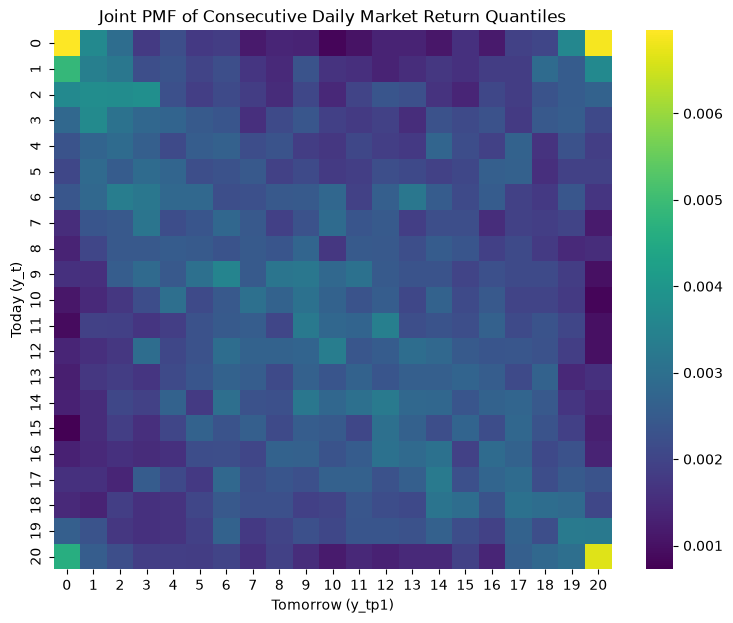

In [17]:
joint_pmf = pd.crosstab(
    df['y_t'],
    df['y_tp1'],
    normalize='all'
)

fig, ax = plt.subplots(figsize=(9, 7))

sns.heatmap(
    joint_pmf,
    cmap='viridis',
    ax=ax
)

ax.set(
    title='Joint PMF of Consecutive Daily Market Return Quantiles',
    xlabel='Tomorrow (y_tp1)',
    ylabel='Today (y_t)'
)

plt.show()

The only obvious pattern I am noticing is that extremely high or low bins seem to be followed by extremely high or low bins suggesting that extreme market returns one day tend to be followed by more extreme market return days the following day. 

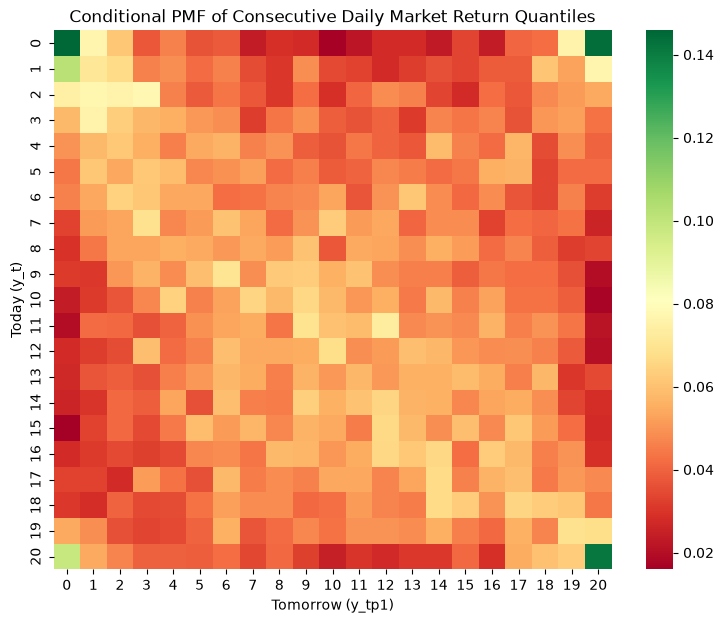

In [19]:
conditional_pmf = pd.crosstab(
    df['y_t'],
    df['y_tp1'],
    normalize='index'
)

fig, ax = plt.subplots(figsize=(9, 7))

sns.heatmap(
    conditional_pmf,
    cmap='RdYlGn',
    ax=ax
)

ax.set(
    title='Conditional PMF of Consecutive Daily Market Return Quantiles',
    xlabel='Tomorrow (y_tp1)',
    ylabel='Today (y_t)'
)

plt.show()

I am seeing the same pattern in the conditional PMF as I did in the joint PMF where extremely high or low bins seem to be followed by extremely high or low bins suggesting that extreme market returns one day tend to be followed by more extreme market return days the following day. Also, I'm not sure if it's the different color scheme, but there also seems to be a slight pattern where market returns today tend to have similar returns tomorrow. 

In [20]:
df.head()

,date,year,month,month_start,trading_day_of_month,mkt_excess_return_pct,risk_free_return_pct,market_return_pct,absolute_market_return_pct,current_direction,next_direction,market_category,next_category,next_return_pct,y_t,y_tp1
0,1926-07-01,1926,7,1926-07-01,1,0.09,0.01,0.10,0.10,Up,Up,Near zero,Small gain,0.46,10,15
1,1926-07-02,1926,7,1926-07-01,2,0.45,0.01,0.46,0.46,Up,Up,Small gain,Small gain,0.18,15,11
2,1926-07-06,1926,7,1926-07-01,3,0.17,0.01,0.18,0.18,Up,Up,Small gain,Near zero,0.10,11,10
3,1926-07-07,1926,7,1926-07-01,4,0.09,0.01,0.10,0.10,Up,Up,Near zero,Small gain,0.23,10,12
4,1926-07-08,1926,7,1926-07-01,5,0.22,0.01,0.23,0.23,Up,Down,Small gain,Small loss,-0.70,12,3


- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 
- How easy is it to predict the market?

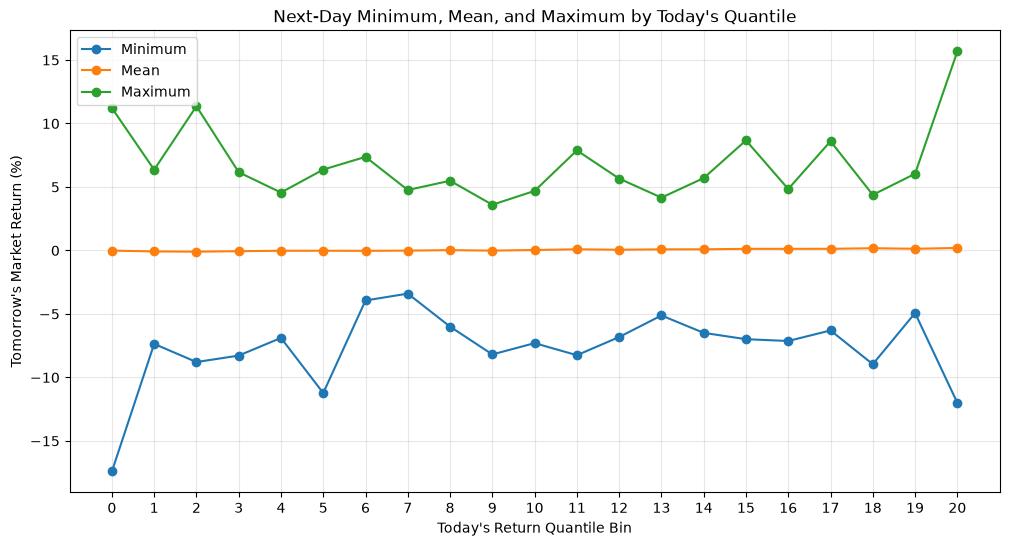

In [24]:
next_day_stats = df.groupby('y_t', observed=False)['next_return_pct'].agg(
    ['mean', 'min', 'max']
)

plt.figure(figsize=(12, 6))

plt.plot(next_day_stats.index, next_day_stats['min'],
         label='Minimum', marker='o')

plt.plot(next_day_stats.index, next_day_stats['mean'],
         label='Mean', marker='o')

plt.plot(next_day_stats.index, next_day_stats['max'],
         label='Maximum', marker='o')

plt.xlabel("Today's Return Quantile Bin")
plt.ylabel("Tomorrow's Market Return (%)")
plt.title("Next-Day Minimum, Mean, and Maximum by Today's Quantile")
plt.xticks(range(21))
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

The mean for tomorrow's market return appears to be relatviely steady around 0 for all of the bins. However, the mix and max seem to be much more extreme at the lower and higher bins suggesting higher variation and volatility in the market returns for those bins. 

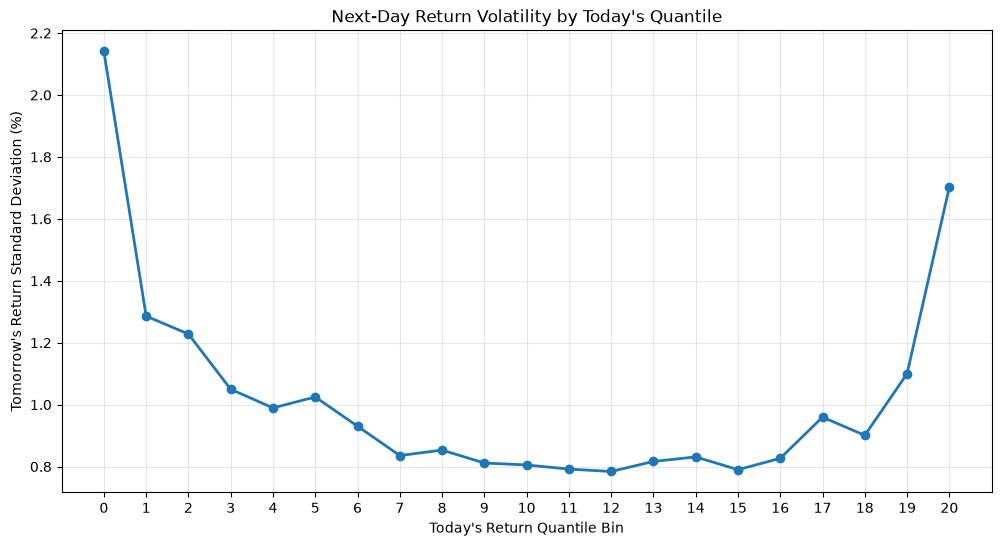

In [26]:
next_std = df.groupby('y_t', observed=False)['next_return_pct'].std()

plt.figure(figsize=(12, 6))

plt.plot(next_std.index, next_std,
         marker='o', linewidth=2)

plt.xlabel("Today's Return Quantile Bin")
plt.ylabel("Tomorrow's Return Standard Deviation (%)")
plt.title("Next-Day Return Volatility by Today's Quantile")
plt.xticks(range(21))
plt.grid(True, alpha=0.3)
plt.show()

Like I mentioned after looking at the min and max plot, we can see that there is much more variation in the higher and lower bins meaning more volatility in tomorrow's market returns for those bins, where the more central bins have a relatively low variation and volatility. 

The market is difficult to predict using only the previous day's return. Although the joint PMF, conditional PMF, and summary statistics may reveal some patterns, such as volatility across bins, these patterns do not necessarily provide us with reliable predictions. The mean tomorrow's return may vary across today's bins, but the minimum and maximum values show that a wide range of outcomes is possible. Similarly, standard deviation only measures whether certain market movements are followed by more volatile days. Overall, historical daily returns may provide some information about future returns and volatility, but still uncertainty remains making predicting the exact direction or size of the next day's market return difficult.